# Ejercicio 10: Modelos de Markov

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

Se modela el clima diario de una ciudad con una **cadena de Markov observable** (inciso 1) y luego la actividad de un turista con un **modelo oculto de Markov** (HMM, inciso 2). Todos los algoritmos (muestreo, forward, backward, Viterbi, Baum-Welch, entrenamiento de Viterbi) se implementan desde cero.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1a, 1b** | Simular la cadena como modelo generativo y graficar secuencias | Distribución estacionaria, duración de rachas |
| **1c** | Re-estimar $\mathbf{A}$ y $\boldsymbol\pi$; efecto de la cantidad y el largo de las secuencias; validez en todas las estaciones | Estimación por conteo; $\boldsymbol\pi$ solo mejora con más secuencias |
| **1d** | Convertir el modelo en oculto y simular | Ocultamiento progresivo, matriz de observación $\mathbf{B}$ |
| **2a** | Secuencia de climas más probable dada una secuencia de comportamientos | Algoritmo de Viterbi |
| **2b** | Entrenar con Viterbi y con Baum-Welch y comparar con los parámetros reales | EM vs. entrenamiento duro |
| **2c** | Clasificar un turista según su primera semana | Verosimilitud bajo varios modelos |

**Contenido**

1. [Teoría](#1.-Teoría)
2. [Implementación](#2.-Implementación)
3. [Inciso 1a y 1b: simulación de la cadena](#3.-Inciso-1a-y-1b:-simulación-de-la-cadena)
4. [Inciso 1c: re-estimación de parámetros](#4.-Inciso-1c:-re-estimación-de-parámetros)
5. [Inciso 1d: modelo oculto](#5.-Inciso-1d:-modelo-oculto)
6. [Inciso 2a: decodificación del clima](#6.-Inciso-2a:-decodificación-del-clima)
7. [Inciso 2b: entrenamiento](#7.-Inciso-2b:-entrenamiento)
8. [Inciso 2c: clasificación de turistas](#8.-Inciso-2c:-clasificación-de-turistas)
9. [Conclusiones](#9.-Conclusiones)

---
## 1. Teoría

### 1.1 Cadena de Markov observable

Una cadena de Markov de $N$ estados queda definida por:

- la **matriz de transición** $\mathbf{A}$, con $a_{ij}=P(q_{t+1}=j\mid q_t=i)$ (cada **fila** suma 1);
- la **distribución inicial** $\boldsymbol\pi$, con $\pi_i=P(q_1=i)$.

La propiedad de Markov dice que el futuro depende del pasado solo a través del estado actual: $P(q_{t+1}\mid q_1,\dots,q_t)=P(q_{t+1}\mid q_t)$. La probabilidad de una secuencia es $P(q_1,\dots,q_T)=\pi_{q_1}\prod_{t=1}^{T-1}a_{q_tq_{t+1}}$.

En este ejercicio: $\mathbf{A}=\begin{pmatrix}0.7&0.3\\0.4&0.6\end{pmatrix}$ y $\boldsymbol\pi=(0.6,\,0.4)$, con estados 1 = **Lluvioso**, 2 = **Soleado**.

**Propiedades útiles.**

- **Distribución estacionaria** $\boldsymbol\pi^*$: cumple $\boldsymbol\pi^*\mathbf{A}=\boldsymbol\pi^*$. Para una cadena de 2 estados con $a_{12}=a$ y $a_{21}=b$ vale $\pi^*=\big(\tfrac{b}{a+b},\tfrac{a}{a+b}\big)$.
- **Duración de las rachas:** el tiempo que la cadena permanece en el estado $i$ es **geométrico** con media $1/(1-a_{ii})$.

**Estimación por máxima verosimilitud.** Con las secuencias observadas, los estimadores son los **conteos relativos**:
$$
\hat a_{ij}=\frac{n_{ij}}{\sum_k n_{ik}}\quad(n_{ij}=\text{cantidad de transiciones }i\to j),\qquad
\hat\pi_i=\frac{\#\{\text{secuencias que empiezan en }i\}}{\#\text{secuencias}}.
$$
Cada fila de $\hat{\mathbf{A}}$ es una proporción binomial/multinomial calculada con $n_i=\sum_kn_{ik}$ observaciones, por lo que su desvío estándar es $\sqrt{a_{ij}(1-a_{ij})/n_i}$ (decae como $1/\sqrt{n_i}$).

### 1.2 Modelo oculto de Markov (HMM)

En un HMM la cadena de estados $q_t$ **no se observa**; solo se observa un símbolo $O_t$ que depende del estado. El modelo es $\lambda=(\mathbf{A},\mathbf{B},\boldsymbol\pi)$ donde $b_i(k)=P(O_t=k\mid q_t=i)$ es la **probabilidad de emisión**.

**Convención de $\mathbf{B}$.** En la guía, $\mathbf{B}$ se da como una matriz de $3\times2$ cuyas **columnas** son los estados (cada columna suma 1) y cuyas filas son los símbolos (Caminar, Comprar, Museo). En el código se usa la **traspuesta**, con **filas = estados**: $B[i,k]=b_i(k)$. Es decir:

| | Caminar | Comprar | Museo |
|:--|:-:|:-:|:-:|
| **Lluvioso** | 0.1 | 0.4 | 0.5 |
| **Soleado** | 0.6 | 0.3 | 0.1 |

(Se interpreta así la Figura 8: con lluvia el turista va sobre todo al museo y a comprar, y con sol suele caminar.)

Los tres problemas clásicos de los HMM (Rabiner) son:

1. **Evaluación:** calcular $P(O\mid\lambda)$ → algoritmo **forward**.
2. **Decodificación:** hallar la secuencia de estados más probable → algoritmo de **Viterbi** (o decodificación posterior con forward-backward).
3. **Aprendizaje:** estimar $\lambda$ a partir de observaciones → **Baum-Welch** (EM) o **entrenamiento de Viterbi**.

### 1.3 Forward, backward y posteriores

Se definen $\alpha_t(i)=P(O_1..O_t,\,q_t=i\mid\lambda)$ y $\beta_t(i)=P(O_{t+1}..O_T\mid q_t=i,\lambda)$ con las recursiones
$$
\alpha_1(i)=\pi_ib_i(O_1),\quad \alpha_{t+1}(j)=\Big[\sum_i\alpha_t(i)a_{ij}\Big]b_j(O_{t+1}),\qquad
\beta_T(i)=1,\quad \beta_t(i)=\sum_ja_{ij}b_j(O_{t+1})\beta_{t+1}(j).
$$
Entonces $P(O\mid\lambda)=\sum_i\alpha_T(i)$ y los **posteriores** son
$$
\gamma_t(i)=P(q_t=i\mid O)=\frac{\alpha_t(i)\beta_t(i)}{P(O)},\qquad
\xi_t(i,j)=P(q_t=i,q_{t+1}=j\mid O)=\frac{\alpha_t(i)\,a_{ij}\,b_j(O_{t+1})\,\beta_{t+1}(j)}{P(O)}.
$$
En el código se usa **reescalado** en cada paso (cada $\alpha_t$ se normaliza dividiendo por $c_t$), de modo que $\log P(O\mid\lambda)=\sum_t\log c_t$ y se evita el desborde numérico en secuencias largas.

### 1.4 Viterbi

Se busca $\hat{\mathbf{q}}=\arg\max_{\mathbf{q}}P(\mathbf{q},O\mid\lambda)$. Con $\delta_t(j)=\max_{q_1..q_{t-1}}P(q_1..q_{t-1},q_t=j,O_1..O_t)$ se tiene $\delta_{t+1}(j)=\max_i[\delta_t(i)a_{ij}]\,b_j(O_{t+1})$, guardando en $\psi_{t+1}(j)$ el $i$ que maximiza; al final se recorre hacia atrás. Se trabaja con logaritmos.

> **Decodificación de Viterbi vs. posterior.** Viterbi maximiza la probabilidad de la **secuencia completa**; en cambio, elegir $\arg\max_i\gamma_t(i)$ en cada instante maximiza la **cantidad esperada de estados correctos**. Los resultados pueden diferir.

### 1.5 Aprendizaje

**Baum-Welch (EM).** En cada iteración, paso E: se calculan $\gamma_t(i)$ y $\xi_t(i,j)$ con los parámetros actuales; paso M: se re-estima
$$
\hat\pi_i=\gamma_1(i),\qquad \hat a_{ij}=\frac{\sum_t\xi_t(i,j)}{\sum_t\gamma_t(i)},\qquad \hat b_i(k)=\frac{\sum_{t:O_t=k}\gamma_t(i)}{\sum_t\gamma_t(i)}
$$
(sumando sobre todas las secuencias). La log-verosimilitud $\log P(O\mid\lambda)$ **no decrece** en ninguna iteración, pero el algoritmo solo garantiza un máximo **local**: hay que probar varias inicializaciones.

**Entrenamiento de Viterbi (*k*-medias segmental).** En lugar de posteriores "blandos", se decodifica cada secuencia con Viterbi, se asigna cada instante a **un único estado** y se re-estiman los parámetros por conteo sobre esos caminos. Es una versión "dura" del EM: maximiza $P(O,\mathbf{q}\mid\lambda)$ conjuntamente en $\lambda$ y en los caminos, no $P(O\mid\lambda)$.

**Ambigüedad de las etiquetas.** Los estados de un HMM estimado están definidos solo **salvo permutación**: la etiqueta "estado 1" puede corresponder a "Soleado". Para comparar con los parámetros reales se elige la permutación más cercana.

### 1.6 Clasificación con varios modelos

Si hay $K$ modelos $\lambda_1,\dots,\lambda_K$ (uno por tipo de turista), una secuencia $O$ se asigna al modelo de **mayor verosimilitud** (o mayor posterior si hay probabilidades a priori):
$$
\hat k=\arg\max_k\ \log P(O\mid\lambda_k)\ \ (+\log P(k)).
$$
Cada $P(O\mid\lambda_k)$ se calcula con el algoritmo forward.

---
## 2. Implementación

Las funciones están agrupadas en cuatro bloques: cadena observable, HMM (muestreo, forward, backward, posteriores y Viterbi), versiones **por lotes** (varias secuencias del mismo largo procesadas a la vez con operaciones matriciales, para poder hacer experimentos repetidos) y entrenamiento (Baum-Welch y entrenamiento de Viterbi).

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2024)

In [2]:
# ======================= Cadena de Markov observable =======================
def muestrear_estados(A, pi, T, rng):
    '''Secuencia de T estados de una cadena de Markov (A: filas = estado actual; pi: distribución inicial).'''
    n = len(pi)
    cumA = np.cumsum(A, axis=1); cumA[:, -1] = 1.0
    u = rng.random(T)
    q = np.empty(T, dtype=int)
    q[0] = min(np.searchsorted(np.cumsum(pi), u[0], side="right"), n - 1)
    for t in range(1, T):
        q[t] = min(np.searchsorted(cumA[q[t - 1]], u[t], side="right"), n - 1)
    return q


def estimar_cadena(secuencias, n):
    '''Estimación de máxima verosimilitud de (A, pi) por conteo de transiciones y de estados iniciales.'''
    cuentas = np.zeros((n, n)); ini = np.zeros(n)
    for q in secuencias:
        ini[q[0]] += 1
        np.add.at(cuentas, (q[:-1], q[1:]), 1)
    fil = cuentas.sum(1, keepdims=True)
    A = np.divide(cuentas, fil, out=np.full_like(cuentas, np.nan), where=fil > 0)
    return A, ini / ini.sum(), cuentas


def distribucion_estacionaria(A):
    '''Vector pi* con pi* A = pi* (autovector izquierdo de autovalor 1).'''
    w, v = np.linalg.eig(A.T)
    p = np.real(v[:, np.argmin(np.abs(w - 1))])
    return p / p.sum()

In [3]:
# ======================= Modelo oculto de Markov =======================
# Convención interna: B[i, k] = P(observar el símbolo k | estado i)  (filas = estados, columnas = símbolos)
def muestrear_hmm(A, B, pi, T, rng):
    q = muestrear_estados(A, pi, T, rng)
    cumB = np.cumsum(B, axis=1); cumB[:, -1] = 1.0
    u = rng.random(T)
    O = np.array([min(np.searchsorted(cumB[i], u[t], side="right"), B.shape[1] - 1) for t, i in enumerate(q)])
    return q, O


def forward(A, B, pi, O):
    '''Algoritmo forward con reescalado. Devuelve alfa (normalizado) y los factores de escala c_t.
    log P(O | modelo) = sum_t log c_t.'''
    T, N = len(O), len(pi)
    alfa = np.zeros((T, N)); c = np.zeros(T)
    a = pi * B[:, O[0]]; c[0] = a.sum(); alfa[0] = a / c[0]
    for t in range(1, T):
        a = (alfa[t - 1] @ A) * B[:, O[t]]; c[t] = a.sum(); alfa[t] = a / c[t]
    return alfa, c


def backward(A, B, O, c):
    T, N = len(O), A.shape[0]
    beta = np.ones((T, N))
    for t in range(T - 2, -1, -1):
        beta[t] = A @ (B[:, O[t + 1]] * beta[t + 1]) / c[t + 1]
    return beta


def log_verosimilitud(A, B, pi, O):
    return float(np.log(forward(A, B, pi, O)[1]).sum())


def posteriores(A, B, pi, O):
    '''gamma_t(i) = P(q_t = i | O)  y  xi_t(i,j) = P(q_t=i, q_{t+1}=j | O).'''
    alfa, c = forward(A, B, pi, O); beta = backward(A, B, O, c)
    gamma = alfa * beta
    xi = alfa[:-1, :, None] * A[None] * (B[:, O[1:]].T * beta[1:])[:, None, :] / c[1:, None, None]
    return gamma, xi, float(np.log(c).sum())


def viterbi(A, B, pi, O):
    '''Secuencia de estados más probable (en log). Devuelve (camino, log P(O, camino)).'''
    T, N = len(O), len(pi)
    with np.errstate(divide="ignore"):
        lA, lB, lpi = np.log(A), np.log(B), np.log(pi)
    delta = np.zeros((T, N)); psi = np.zeros((T, N), dtype=int)
    delta[0] = lpi + lB[:, O[0]]
    for t in range(1, T):
        cand = delta[t - 1][:, None] + lA
        psi[t] = cand.argmax(0); delta[t] = cand.max(0) + lB[:, O[t]]
    q = np.zeros(T, dtype=int); q[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):
        q[t] = psi[t + 1, q[t + 1]]
    return q, float(delta[-1].max())

In [4]:
# ======================= Muestreo por lotes =======================
def muestrear_estados_lote(A, pi, K, T, rng):
    '''K secuencias de estados de largo T (matriz K x T), generadas en paralelo.'''
    cumA = np.cumsum(A, axis=1); cumPi = np.cumsum(pi)
    q = np.empty((K, T), dtype=int)
    q[:, 0] = (rng.random(K)[:, None] > cumPi[None, :-1]).sum(1)
    for t in range(1, T):
        q[:, t] = (rng.random(K)[:, None] > cumA[q[:, t - 1], :-1]).sum(1)
    return q


def muestrear_hmm_lote(A, B, pi, K, T, rng):
    '''K secuencias (estados ocultos q y observaciones O, ambas K x T).'''
    q = muestrear_estados_lote(A, pi, K, T, rng)
    cumB = np.cumsum(B, axis=1)
    O = (rng.random((K, T))[..., None] > cumB[q][..., :-1]).sum(-1)
    return q, O

In [5]:
# ======================= Versión por lotes (K secuencias de igual largo T) =======================
def forward_lote(A, B, pi, O):
    '''Forward con reescalado para un lote de secuencias O (K x T). Devuelve alfa (K,T,N) y c (K,T).'''
    K, T = O.shape; N = len(pi)
    alfa = np.zeros((K, T, N)); c = np.zeros((K, T))
    a = pi[None] * B[:, O[:, 0]].T; c[:, 0] = a.sum(1); alfa[:, 0] = a / c[:, :1]
    for t in range(1, T):
        a = (alfa[:, t - 1] @ A) * B[:, O[:, t]].T; c[:, t] = a.sum(1); alfa[:, t] = a / c[:, t:t + 1]
    return alfa, c


def posteriores_lote(A, B, pi, O):
    K, T = O.shape; N = len(pi)
    alfa, c = forward_lote(A, B, pi, O)
    beta = np.ones((K, T, N))
    for t in range(T - 2, -1, -1):
        beta[:, t] = (B[:, O[:, t + 1]].T * beta[:, t + 1]) @ A.T / c[:, t + 1:t + 2]
    gamma = alfa * beta
    xi = alfa[:, :-1, :, None] * A[None, None] * (B[:, O[:, 1:]].transpose(1, 2, 0) * beta[:, 1:])[:, :, None, :] \
        / c[:, 1:, None, None]
    return gamma, xi, float(np.log(c).sum())


def viterbi_lote(A, B, pi, O):
    K, T = O.shape; N = len(pi)
    with np.errstate(divide="ignore"):
        lA, lB, lpi = np.log(A), np.log(B), np.log(pi)
    delta = lpi[None] + lB[:, O[:, 0]].T
    psi = np.zeros((K, T, N), dtype=int)
    for t in range(1, T):
        cand = delta[:, :, None] + lA[None]
        psi[:, t] = cand.argmax(1); delta = cand.max(1) + lB[:, O[:, t]].T
    q = np.zeros((K, T), dtype=int); q[:, -1] = delta.argmax(1)
    for t in range(T - 2, -1, -1):
        q[:, t] = np.take_along_axis(psi[:, t + 1], q[:, t + 1:t + 2], axis=1)[:, 0]
    return q, float(delta.max(1).sum())

In [6]:
# ======================= Entrenamiento =======================
def baum_welch(O, A0, B0, pi0, n_iter=500, tol=1e-4):
    '''Baum-Welch (EM). O: matriz K x T con K secuencias de largo T. Devuelve (A, B, pi, historia de log-verosimilitud).
    Se detiene cuando la log-verosimilitud mejora menos de `tol`.'''
    A, B, pi = A0.copy(), B0.copy(), pi0.copy()
    N, M = B.shape; K, T = O.shape; hist = []
    for it in range(n_iter):
        gamma, xi, ll = posteriores_lote(A, B, pi, O); hist.append(ll)
        if it > 0 and hist[-1] - hist[-2] < tol:
            break
        pi = gamma[:, 0].sum(0) / K
        A = xi.sum((0, 1)); A = A / A.sum(1, keepdims=True)
        B = np.stack([gamma[O == k].sum(0) for k in range(M)], axis=1); B = B / B.sum(1, keepdims=True)
    return A, B, pi, np.array(hist)


def entrenar_viterbi(O, A0, B0, pi0, n_iter=200, suav=1e-3):
    '''Entrenamiento de Viterbi (k-medias segmental): se decodifica cada secuencia con el modelo actual y se
    re-estima contando sobre los caminos decodificados (con una pequeña suavización `suav` para evitar ceros).
    Se detiene cuando los caminos ya no cambian.'''
    A, B, pi = A0.copy(), B0.copy(), pi0.copy()
    N, M = B.shape; hist = []; previo = None
    for it in range(n_iter):
        q, lp = viterbi_lote(A, B, pi, O); hist.append(lp)
        if previo is not None and np.array_equal(q, previo):
            break
        previo = q
        pi_n = np.full(N, suav); A_n = np.full((N, N), suav); B_n = np.full((N, M), suav)
        np.add.at(pi_n, q[:, 0], 1); np.add.at(A_n, (q[:, :-1].ravel(), q[:, 1:].ravel()), 1); np.add.at(B_n, (q.ravel(), O.ravel()), 1)
        pi = pi_n / pi_n.sum(); A = A_n / A_n.sum(1, keepdims=True); B = B_n / B_n.sum(1, keepdims=True)
    return A, B, pi, np.array(hist)


def parametros_aleatorios(N, M, rng):
    return rng.dirichlet(np.ones(N), size=N), rng.dirichlet(np.ones(M), size=N), rng.dirichlet(np.ones(N))


def alinear_estados(A, B, pi, A_ref, B_ref, pi_ref):
    '''Los estados de un HMM estimado están definidos salvo permutación: se elige la permutación más cercana a la referencia.'''
    import itertools
    mejor, mejor_err = None, np.inf
    for perm in itertools.permutations(range(len(pi))):
        p = list(perm)
        err = np.abs(A[np.ix_(p, p)] - A_ref).sum() + np.abs(B[p] - B_ref).sum() + np.abs(pi[p] - pi_ref).sum()
        if err < mejor_err:
            mejor, mejor_err = p, err
    return A[np.ix_(mejor, mejor)], B[mejor], pi[mejor], mejor


def ajustar_con_reinicios(O, N, M, metodo, n_reinicios, rng, **kw):
    '''Ajusta con varios inicios aleatorios y devuelve el mejor según el criterio propio del método
    (log-verosimilitud para Baum-Welch; log P(O, camino) para Viterbi) junto con todos los resultados.'''
    res = []
    for _ in range(n_reinicios):
        A0, B0, p0 = parametros_aleatorios(N, M, rng)
        res.append(metodo(O, A0, B0, p0, **kw))
    return max(res, key=lambda r: r[3][-1]), res

### Verificación de la implementación

Antes de usar los algoritmos se comprueban contra el **cálculo por fuerza bruta**: para una secuencia corta ($T=7$) se enumeran las $2^7$ secuencias de estados posibles y se compara con el forward (suma de todas las probabilidades) y con Viterbi (la de mayor probabilidad). También se verifica que los posteriores estén normalizados y que las versiones por lotes coincidan con las de una sola secuencia.

In [7]:
# ---- Parámetros del ejercicio ----
ESTADOS = ["Lluvioso", "Soleado"]
SIMBOLOS = ["Caminar", "Comprar", "Museo"]
A = np.array([[0.7, 0.3],
              [0.4, 0.6]])
pi = np.array([0.6, 0.4])
B_guia = np.array([[0.1, 0.6],      # Caminar  (columna = estado)
                   [0.4, 0.3],      # Comprar
                   [0.5, 0.1]])     # Museo
B = B_guia.T                         # convención interna: filas = estados
print("Columnas de B_guia suman 1:", B_guia.sum(0), "   filas de B (por estado) suman 1:", B.sum(1), "   filas de A suman 1:", A.sum(1))

# ---- Fuerza bruta para T = 7 ----
q_v, O_v = muestrear_hmm(A, B, pi, 7, rng)
total, mejor = 0.0, (-1, None)
for cam in itertools.product(range(2), repeat=7):
    p = pi[cam[0]] * B[cam[0], O_v[0]]
    for t in range(1, 7):
        p *= A[cam[t - 1], cam[t]] * B[cam[t], O_v[t]]
    total += p
    if p > mejor[0]: mejor = (p, cam)

print(f"\nP(O): forward = {np.exp(log_verosimilitud(A, B, pi, O_v)):.10e}   fuerza bruta = {total:.10e}")
qv, lv = viterbi(A, B, pi, O_v)
print(f"Viterbi: camino {qv}  P(O,q*) = {np.exp(lv):.6e}   |  fuerza bruta: camino {np.array(mejor[1])}  P = {mejor[0]:.6e}")
gam, xi_, _ = posteriores(A, B, pi, O_v)
print("Los posteriores gamma_t suman 1 en cada t:", np.allclose(gam.sum(1), 1), "   xi_t suma 1:", np.allclose(xi_.sum((1, 2)), 1))

# ---- Lotes vs. una sola secuencia ----
Ol = np.array([muestrear_hmm(A, B, pi, 50, rng)[1] for _ in range(4)])
gl, xl, _ = posteriores_lote(A, B, pi, Ol); ql, _ = viterbi_lote(A, B, pi, Ol)
print("Lotes = una por una (posteriores y Viterbi):",
      all(np.allclose(gl[k], posteriores(A, B, pi, Ol[k])[0]) and np.array_equal(ql[k], viterbi(A, B, pi, Ol[k])[0]) for k in range(4)))

Columnas de B_guia suman 1: [1. 1.]    filas de B (por estado) suman 1: [1. 1.]    filas de A suman 1: [1. 1.]

P(O): forward = 4.6612643136e-04   fuerza bruta = 4.6612643136e-04
Viterbi: camino [1 1 1 1 0 0 0]  P(O,q*) = 4.389396e-05   |  fuerza bruta: camino [1 1 1 1 0 0 0]  P = 4.389396e-05
Los posteriores gamma_t suman 1 en cada t: True    xi_t suma 1: True
Lotes = una por una (posteriores y Viterbi): True


---
## 3. Inciso 1a y 1b: simulación de la cadena

### 1a. Modelo generativo

Para generar una secuencia: se sortea el estado inicial con $\boldsymbol\pi$ y luego, en cada día, se sortea el estado siguiente con la fila de $\mathbf{A}$ correspondiente al estado actual. Ejemplo con 60 días:

In [8]:
q = muestrear_estados(A, pi, 60, rng)
print("Secuencia de 60 días (L = lluvioso, S = soleado):")
print("".join("LS"[i] for i in q))
print("\nFracción de días lluviosos en esta secuencia:", round(float((q == 0).mean()), 3))

Secuencia de 60 días (L = lluvioso, S = soleado):
SSSSLLSSLSSSLLLLLSLLLSSSSLSLSSLSLSSLLSSLLLLLLSLLLLSSLSSSLLLL

Fracción de días lluviosos en esta secuencia: 0.533


### 1b. Varias secuencias y su gráfico

Se generan 8 secuencias de 60 días. En la figura, cada fila es una secuencia (azul = lluvioso, amarillo = soleado); debajo, una de ellas como gráfico de escalones.

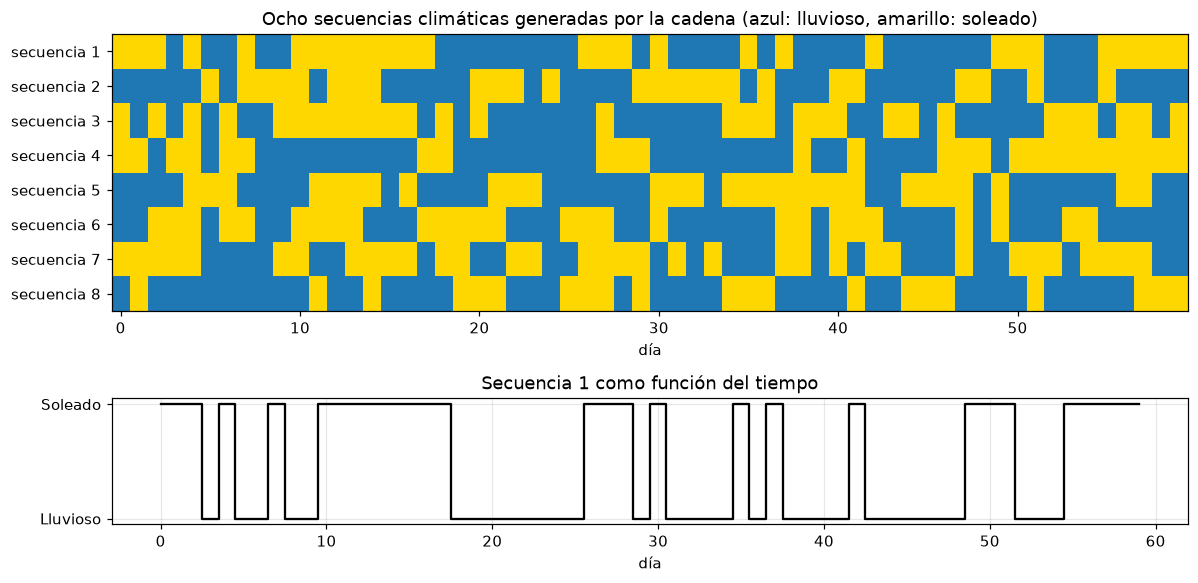

In [9]:
K, T = 8, 60
Q = muestrear_estados_lote(A, pi, K, T, rng)
colores = ListedColormap(["tab:blue", "gold"])

fig = plt.figure(figsize=(11, 5.4))
gs = fig.add_gridspec(2, 1, height_ratios=[2.2, 1])
ax = fig.add_subplot(gs[0]); ax.imshow(Q, cmap=colores, aspect="auto", interpolation="nearest")
ax.set(yticks=range(K), yticklabels=[f"secuencia {k+1}" for k in range(K)], xlabel="día", title="Ocho secuencias climáticas generadas por la cadena (azul: lluvioso, amarillo: soleado)")
ax.grid(False)
ax = fig.add_subplot(gs[1]); ax.step(range(T), Q[0], where="mid", color="k"); ax.set_yticks([0, 1]); ax.set_yticklabels(ESTADOS)
ax.set(xlabel="día", title="Secuencia 1 como función del tiempo")
plt.tight_layout(); plt.show()

### Comprobación del modelo generativo

Con una secuencia muy larga ($T=10^5$) se contrastan tres propiedades con la teoría: (i) la **fracción de tiempo** en cada estado debe tender a la distribución estacionaria $\boldsymbol\pi^*$; (ii) las **frecuencias de transición** deben tender a $\mathbf{A}$; (iii) la **duración de las rachas** debe ser geométrica con media $1/(1-a_{ii})$.

Distribución estacionaria teórica  π* = [0.5714 0.4286]   (b/(a+b), a/(a+b) con a=0.3, b=0.4)
Fracción de tiempo en cada estado      = [0.5754 0.4246]
Transiciones estimadas:
 [[0.7039 0.2961]
 [0.4012 0.5988]]


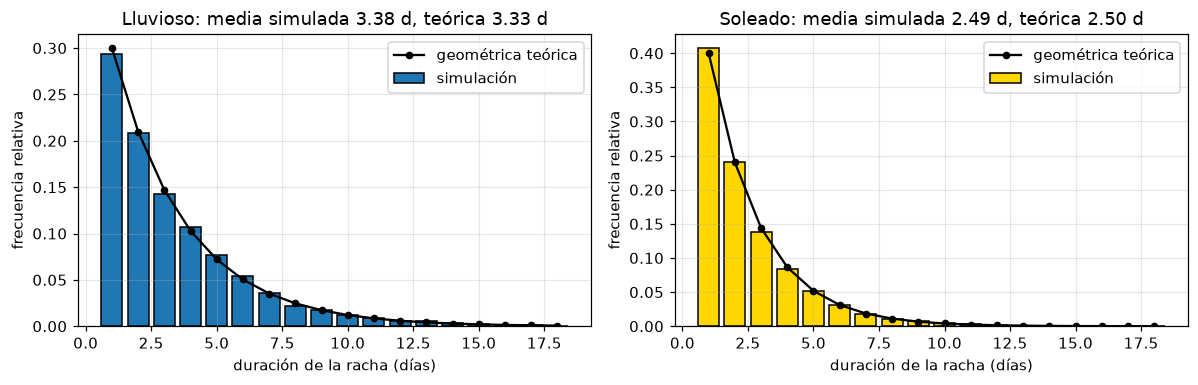

In [10]:
pi_est = distribucion_estacionaria(A)
ql = muestrear_estados(A, pi, 100_000, rng)
Ah_l, _, _ = estimar_cadena([ql], 2)

print("Distribución estacionaria teórica  π* =", pi_est.round(4), "  (b/(a+b), a/(a+b) con a=0.3, b=0.4)")
print("Fracción de tiempo en cada estado      =", np.bincount(ql) / len(ql))
print("Transiciones estimadas:\n", Ah_l.round(4))

# rachas
cambios = np.flatnonzero(np.diff(ql)) + 1
bordes = np.concatenate([[0], cambios, [len(ql)]]); largos = np.diff(bordes); estado_racha = ql[bordes[:-1]]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for i, ax in enumerate(axs):
    L = largos[estado_racha == i]; mx = 18
    ax.bar(np.arange(1, mx + 1), [np.mean(L == k) for k in range(1, mx + 1)], color=["tab:blue", "gold"][i], edgecolor="k", label="simulación")
    ax.plot(np.arange(1, mx + 1), (1 - A[i, i]) * A[i, i] ** (np.arange(1, mx + 1) - 1), "ko-", ms=4, label="geométrica teórica")
    ax.set(xlabel="duración de la racha (días)", ylabel="frecuencia relativa", title=f"{ESTADOS[i]}: media simulada {L.mean():.2f} d, teórica {1/(1-A[i,i]):.2f} d")
    ax.legend()
plt.tight_layout(); plt.show()

**Observaciones.**

- **Distribución estacionaria:** en una secuencia de $10^5$ días la fracción de tiempo es $(0.575,\,0.425)$, muy cerca de la teórica $\boldsymbol\pi^*=(4/7,\,3/7)=(0.571,\,0.429)$. Hay que distinguir $\boldsymbol\pi^*$ (a lo que tiende la fracción de tiempo) de $\boldsymbol\pi=(0.6,0.4)$ (la distribución del **primer** día): son distintas porque el modelo no parte del régimen estacionario.
- **Transiciones:** las frecuencias estimadas, $\begin{pmatrix}0.704&0.296\\0.401&0.599\end{pmatrix}$, reproducen $\mathbf{A}$.
- **Duración de las rachas:** la longitud de las rachas sigue la distribución **geométrica** teórica, con media simulada de $3.38$ días de lluvia (teórica $1/0.3=3.33$) y $2.49$ días de sol (teórica $1/0.4=2.5$). La mayoría de las rachas son muy cortas: el 30 % de las rachas de lluvia y el 40 % de las de sol duran un solo día.
- En el gráfico de las ocho secuencias no se ve ningún patrón regular: cada una es una realización distinta del mismo proceso.

---
## 4. Inciso 1c: re-estimación de parámetros

### 4.1 Una estimación

Con las secuencias generadas se re-estiman $\mathbf{A}$ y $\boldsymbol\pi$ por conteo. Se muestran dos casos: **una** secuencia de 100 días y **50** secuencias de 100 días.

In [11]:
for K_, T_ in [(1, 100), (50, 100)]:
    Qe = muestrear_estados_lote(A, pi, K_, T_, rng)
    Ah, ph, cuentas = estimar_cadena(Qe, 2)
    print(f"--- K = {K_} secuencia(s) de T = {T_} días ---")
    print("Conteos n_ij:\n", cuentas.astype(int))
    print("Â =\n", Ah.round(3), "\nπ̂ =", ph.round(3), "\n")
print("Valores reales:  A =", A.tolist(), "  π =", pi.tolist())

--- K = 1 secuencia(s) de T = 100 días ---
Conteos n_ij:
 [[45 19]
 [18 17]]
Â =
 [[0.703 0.297]
 [0.514 0.486]] 
π̂ = [1. 0.] 

--- K = 50 secuencia(s) de T = 100 días ---
Conteos n_ij:
 [[1930  860]
 [ 866 1294]]
Â =
 [[0.692 0.308]
 [0.401 0.599]] 
π̂ = [0.54 0.46] 

Valores reales:  A = [[0.7, 0.3], [0.4, 0.6]]   π = [0.6, 0.4]


### 4.2 Efecto de la cantidad $K$ y del largo $T$ de las secuencias

Se estiman los parámetros con $K\in\{1,5,20,100\}$ secuencias de largo $T\in\{5,20,100,500\}$, repitiendo cada configuración 300 veces para promediar el error (error absoluto medio de las entradas de $\hat{\mathbf{A}}$ y de $\hat{\boldsymbol\pi}$).

,T=5,T=20,T=100,T=500
error medio de Â,,,,
K=1,0.306,0.142,0.055,0.024
K=5,0.134,0.060,0.025,0.011
K=20,0.063,0.027,0.012,0.005
K=100,0.028,0.012,0.005,0.002


,T=5,T=20,T=100,T=500
error medio de π̂,,,,
K=1,0.474,0.479,0.483,0.481
K=5,0.175,0.161,0.172,0.143
K=20,0.086,0.084,0.087,0.086
K=100,0.040,0.038,0.039,0.040


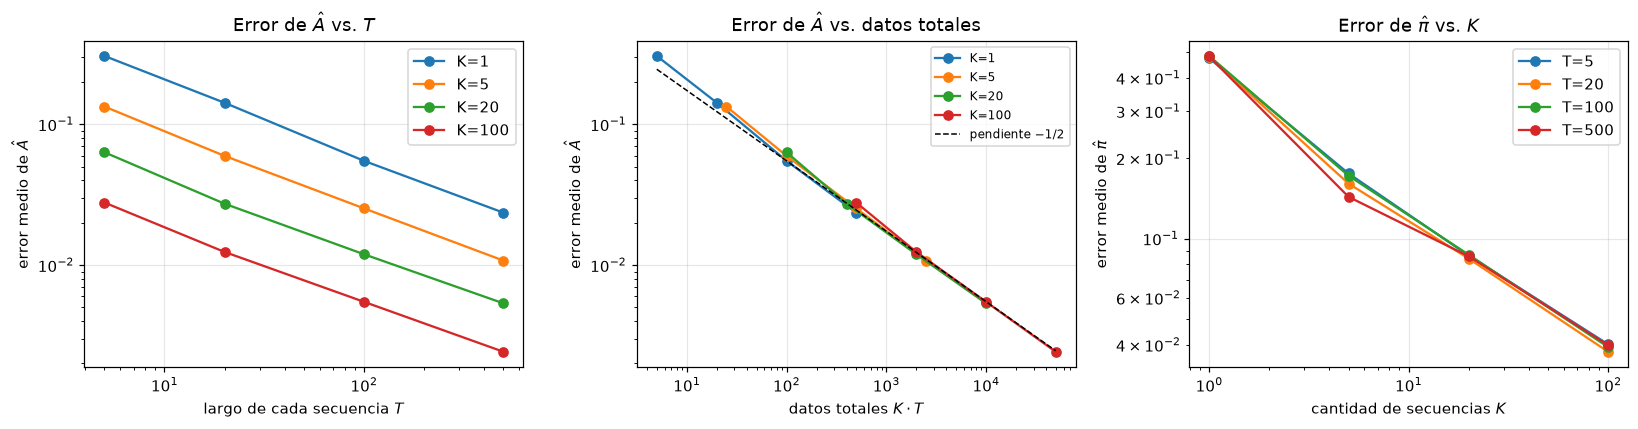

In [12]:
Ks = [1, 5, 20, 100]; Ts = [5, 20, 100, 500]; R = 300
errA = np.zeros((len(Ks), len(Ts))); errP = np.zeros_like(errA)
for a, K_ in enumerate(Ks):
    for b, T_ in enumerate(Ts):
        eA, eP = [], []
        for _ in range(R):
            Ah, ph, _ = estimar_cadena(muestrear_estados_lote(A, pi, K_, T_, rng), 2)
            eA.append(np.nanmean(np.abs(Ah - A))); eP.append(np.abs(ph - pi).mean())
        errA[a, b] = np.nanmean(eA); errP[a, b] = np.mean(eP)

display(pd.DataFrame(errA, index=[f"K={k}" for k in Ks], columns=[f"T={t}" for t in Ts]).round(3).rename_axis("error medio de Â"))
display(pd.DataFrame(errP, index=[f"K={k}" for k in Ks], columns=[f"T={t}" for t in Ts]).round(3).rename_axis("error medio de π̂"))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for a, K_ in enumerate(Ks): axs[0].loglog(Ts, errA[a], "o-", label=f"K={K_}")
axs[0].set(xlabel="largo de cada secuencia $T$", ylabel="error medio de $\\hat{A}$", title="Error de $\\hat{A}$ vs. $T$"); axs[0].legend()
for a, K_ in enumerate(Ks): axs[1].loglog(np.array(Ts) * K_, errA[a], "o-", label=f"K={K_}")
ref_n = np.array([5.0, 5e4]); axs[1].loglog(ref_n, errA[0, 2] * 10 / np.sqrt(ref_n), "k--", lw=1, label="pendiente −1/2")
axs[1].set(xlabel="datos totales $K\\cdot T$", ylabel="error medio de $\\hat{A}$", title="Error de $\\hat{A}$ vs. datos totales"); axs[1].legend(fontsize=8)
for b, T_ in enumerate(Ts): axs[2].loglog(Ks, errP[:, b], "o-", label=f"T={T_}")
axs[2].set(xlabel="cantidad de secuencias $K$", ylabel="error medio de $\\hat{\\pi}$", title="Error de $\\hat{\\pi}$ vs. $K$"); axs[2].legend()
plt.tight_layout(); plt.show()

**Observaciones.**

- **Con una sola secuencia de 100 días**, $\hat{\boldsymbol\pi}=(1,0)$: $\hat{\boldsymbol\pi}$ solo se calcula con el **primer día** de cada secuencia, así que con una única secuencia es una muestra de tamaño 1 y solo puede valer $(1,0)$ o $(0,1)$. Con 50 secuencias se obtiene $(0.54,0.46)$. En cambio $\hat{\mathbf{A}}$ ya es razonable con una sola secuencia, aunque la segunda fila $(0.51,0.49)$ se aleja de $(0.4,0.6)$ porque se basa en solo 35 transiciones que salen del estado soleado (con 50 secuencias: $(0.40,0.60)$).
- **$\hat{\mathbf{A}}$ depende de la cantidad total de transiciones, $K\cdot T$**, no de cómo se reparten: por ejemplo, $K=1,T=100$; $K=5,T=20$ y $K=20,T=5$ (todas con unas 100 transiciones) tienen errores parecidos (0.055, 0.060 y 0.063). El gráfico central lo confirma: todas las configuraciones caen sobre una misma recta de pendiente $-1/2$ (error $\propto1/\sqrt{K\,T}$).
- **$\hat{\boldsymbol\pi}$ depende solo de la cantidad de secuencias $K$** y no de su largo: el error es $\approx0.48$ con $K=1$ para cualquier $T$, $0.086$ con $K=20$ y $0.04$ con $K=100$ (decae como $1/\sqrt K$). Alargar las secuencias no ayuda a estimar $\boldsymbol\pi$; hay que **observar más secuencias**.
- **Fórmula del desvío:** el desvío observado de $\hat a_{11}$ coincide con la fórmula $\sqrt{a(1-a)/n_1}$ ($0.0613$ vs. $0.0609$ con $T=100$, $0.0265$ vs. $0.0271$ con $T=500$, $0.0135$ vs. $0.0136$ con $T=2000$); con $T=20$ el desvío real es algo mayor ($0.153$ vs. $0.139$) porque $n_1$ es chico y aleatorio.
- *(Nota técnica:* con secuencias muy cortas ($K=1$, $T=5$) a veces un estado no tiene transiciones de salida y su fila de $\hat{\mathbf{A}}$ no está definida; esas filas se ignoran al promediar el error.)

### 4.3 Comprobación de la fórmula del desvío estándar

Según la teoría, $\mathrm{desv}(\hat a_{11})\approx\sqrt{a_{11}(1-a_{11})/n_1}$ con $n_1\approx(T-1)\pi^*_1$ transiciones que salen del estado 1. Se compara con el desvío observado en 2000 repeticiones con una sola secuencia:

In [13]:
filas = []
for T_ in [20, 100, 500, 2000]:
    est = []
    for _ in range(2000):
        Ah, _, _ = estimar_cadena(muestrear_estados_lote(A, pi, 1, T_, rng), 2); est.append(Ah[0, 0])
    est = np.array(est); est = est[~np.isnan(est)]
    n1 = (T_ - 1) * pi_est[0]
    filas.append({"T": T_, "media de â_11": est.mean(), "desv. observado": est.std(), "desv. teórico": np.sqrt(0.7 * 0.3 / n1)})
display(pd.DataFrame(filas).set_index("T").round(4))

,media de â_11,desv. observado,desv. teórico
T,,,
20,0.6740,0.1533,0.1391
100,0.6940,0.0613,0.0609
500,0.6986,0.0265,0.0271
2000,0.6995,0.0135,0.0136


### 4.4 ¿Es válido este modelo para todas las estaciones del año?

El modelo supone una **única matriz $\mathbf{A}$ constante** (cadena **homogénea**) y memoria de **un solo día**. Para ver qué pasa si el clima cambia con la estación, se simula un caso **ilustrativo** (los valores son inventados para este ejemplo): en "verano" llueve poco y en "invierno" mucho,

$$
\mathbf{A}_{\text{verano}}=\begin{pmatrix}0.4&0.6\\0.1&0.9\end{pmatrix},\qquad
\mathbf{A}_{\text{invierno}}=\begin{pmatrix}0.85&0.15\\0.5&0.5\end{pmatrix}.
$$

Se ajusta **una** matriz con los datos de todo el año y se la compara con un modelo **por estación**, midiendo la log-verosimilitud por día sobre datos nuevos de cada estación.

In [14]:
A_ver = np.array([[0.4, 0.6], [0.1, 0.9]]); A_inv = np.array([[0.85, 0.15], [0.5, 0.5]])
Qv = muestrear_estados_lote(A_ver, np.array([0.2, 0.8]), 20, 90, rng); Qi = muestrear_estados_lote(A_inv, np.array([0.8, 0.2]), 20, 90, rng)
Qv_t = muestrear_estados_lote(A_ver, np.array([0.2, 0.8]), 200, 90, rng); Qi_t = muestrear_estados_lote(A_inv, np.array([0.8, 0.2]), 200, 90, rng)

A_pool, _, _ = estimar_cadena(np.vstack([Qv, Qi]), 2); A_v_h, _, _ = estimar_cadena(Qv, 2); A_i_h, _, _ = estimar_cadena(Qi, 2)


def ll_dia(Am, Qs):
    return np.mean([np.log(Am[q[:-1], q[1:]]).mean() for q in Qs])


print("Matriz única (todo el año):\n", A_pool.round(3), "\n  π* =", distribucion_estacionaria(A_pool).round(3))
print("Verano  estimada:\n", A_v_h.round(3), "\n  π* =", distribucion_estacionaria(A_v_h).round(3))
print("Invierno estimada:\n", A_i_h.round(3), "\n  π* =", distribucion_estacionaria(A_i_h).round(3))
tabla = pd.DataFrame({"modelo único": [ll_dia(A_pool, Qv_t), ll_dia(A_pool, Qi_t)],
                      "modelo por estación": [ll_dia(A_v_h, Qv_t), ll_dia(A_i_h, Qi_t)]}, index=["datos de verano", "datos de invierno"])
tabla["pérdida por día (nats)"] = tabla["modelo por estación"] - tabla["modelo único"]
print("\nLog-verosimilitud por día en datos nuevos (mayor es mejor):")
display(tabla.round(4))

Matriz única (todo el año):
 [[0.771 0.229]
 [0.182 0.818]] 
  π* = [0.442 0.558]
Verano  estimada:
 [[0.364 0.636]
 [0.096 0.904]] 
  π* = [0.131 0.869]
Invierno estimada:
 [[0.843 0.157]
 [0.488 0.512]] 
  π* = [0.756 0.244]

Log-verosimilitud por día en datos nuevos (mayor es mejor):


,modelo único,modelo por estación,pérdida por día (nats)
datos de verano,-0.4467,-0.3775,0.0692
datos de invierno,-0.5594,-0.4855,0.0739


**Observaciones.**

- **No, el modelo no es válido para todas las estaciones.** La cadena supone una **única matriz $\mathbf{A}$ constante en el tiempo** (homogénea) y memoria de **un solo día**. Si el clima cambia con la estación, la matriz ajustada con todo el año, $\begin{pmatrix}0.77&0.23\\0.18&0.82\end{pmatrix}$ con $\boldsymbol\pi^*=(0.44,0.56)$, es un **promedio que no describe a ninguna estación**: en el ejemplo, la fracción de días lluviosos a largo plazo es $0.13$ en verano y $0.76$ en invierno.
- **Costo:** con datos nuevos, el modelo único pierde unos $0.07$ nats por día respecto del modelo por estación (en 90 días, la secuencia es unas $e^{6}\approx500$ veces menos verosímil).
- **Alternativas:** (i) un modelo (o una matriz $\mathbf{A}$) **por estación**; (ii) un modelo cuya matriz cambie con el tiempo, $\mathbf{A}(t)$; (iii) incorporar la estación como **variable oculta** (un HMM, que lleva a este mismo tipo de modelos); (iv) cadenas de **orden mayor** si el clima de hoy depende de más de un día. Además, la propiedad de que las rachas son geométricas es poco realista para el clima real.
- *(Los valores de $\mathbf{A}_{\text{verano}}$ y $\mathbf{A}_{\text{invierno}}$ son inventados para ilustrar el efecto; no son datos reales.)*

---
## 5. Inciso 1d: modelo oculto

### ¿Cómo convertir la cadena en un modelo oculto de Markov?

Se deja de **observar el estado** (el clima) y se agrega una **capa de observación**: en cada día se emite un símbolo $O_t$ cuya distribución depende del clima, $P(O_t=k\mid q_t=i)=b_i(k)$. Los parámetros $\mathbf{A}$ y $\boldsymbol\pi$ de la cadena se conservan y se agrega la **matriz de emisión** $\mathbf{B}$. La cadena de estados sigue siendo markoviana, pero ahora está **oculta**; lo que se ve ya no es markoviano de primer orden.

### Ocultamiento progresivo

Siguiendo la sugerencia de la guía, se parte de $\mathbf{B}=\mathbf{I}$ (el clima se observa sin error: es la cadena observable) y se la "oculta" de forma progresiva con
$$
\mathbf{B}_\varepsilon=\begin{pmatrix}1-\varepsilon&\varepsilon\\ \varepsilon&1-\varepsilon\end{pmatrix}
$$
(el símbolo emitido coincide con el clima con probabilidad $1-\varepsilon$; por ejemplo, un pronóstico o un sensor con errores). Con $\varepsilon=0.5$ el símbolo no dice nada del clima. Al final (sección 6) se pasa a la $\mathbf{B}$ de la guía, con 3 símbolos.

Se simula una secuencia de 60 días para cada $\varepsilon$ con el **mismo** clima oculto:

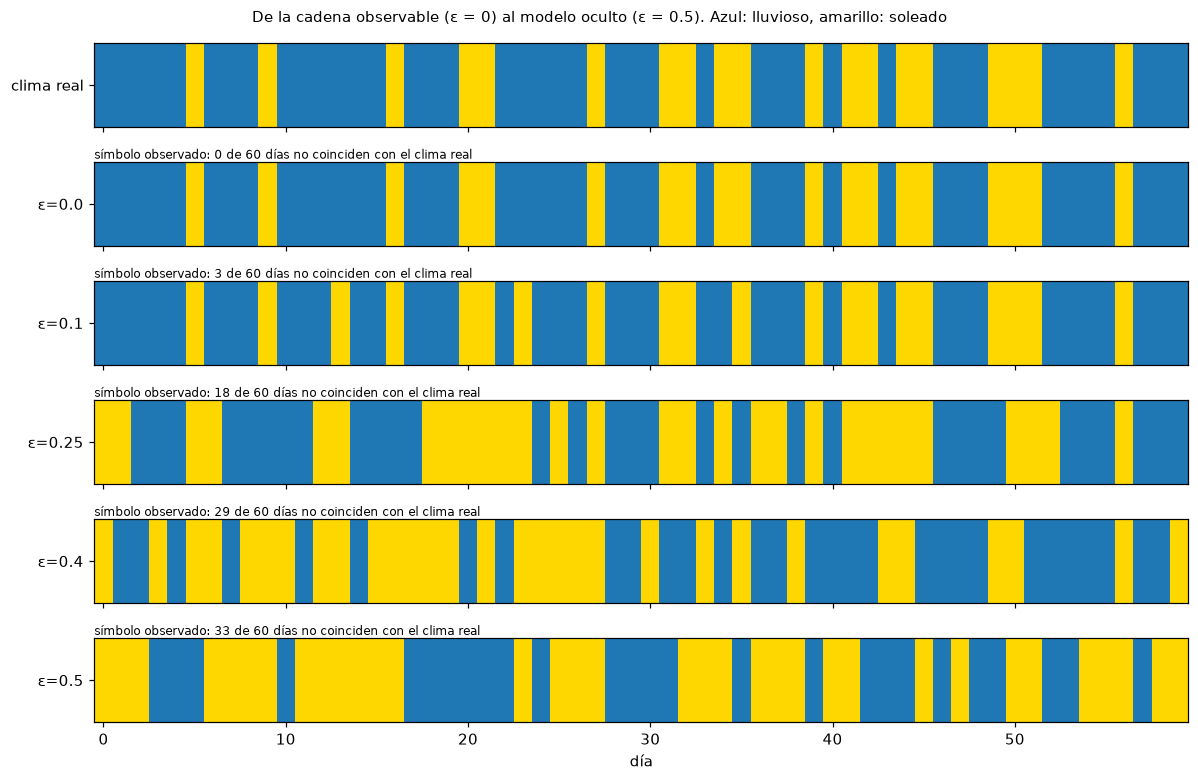

In [15]:
epsilons = [0.0, 0.1, 0.25, 0.4, 0.5]
T_d = 60
q_oculto = muestrear_estados(A, pi, T_d, rng)
fig, axs = plt.subplots(len(epsilons) + 1, 1, figsize=(11, 1.0 * (len(epsilons) + 1) + 1.2), sharex=True)
axs[0].imshow(q_oculto[None], cmap=colores, aspect="auto", interpolation="nearest"); axs[0].set_yticks([0]); axs[0].set_yticklabels(["clima real"]); axs[0].grid(False)
for ax, e in zip(axs[1:], epsilons):
    Be = np.array([[1 - e, e], [e, 1 - e]])
    cumB = np.cumsum(Be, 1); Oe = (rng.random(T_d)[:, None] > cumB[q_oculto][:, :-1]).sum(1)
    ax.imshow(Oe[None], cmap=colores, aspect="auto", interpolation="nearest"); ax.set_yticks([0]); ax.set_yticklabels([f"ε={e}"]); ax.grid(False)
    ax.set_title(f"símbolo observado: {int((Oe != q_oculto).sum())} de {T_d} días no coinciden con el clima real", fontsize=8, loc="left", pad=2)
axs[-1].set_xlabel("día"); plt.suptitle("De la cadena observable (ε = 0) al modelo oculto (ε = 0.5). Azul: lluvioso, amarillo: soleado", fontsize=10)
plt.tight_layout(); plt.show()

### ¿Cuánto se puede recuperar el clima? ¿Qué le pasa a $\hat{\mathbf{A}}$ si se ignora que está oculto?

Con $\varepsilon$ creciente se comparan tres cantidades sobre 100 secuencias de 200 días:

1. **Precisión de creer en el símbolo observado** ($=1-\varepsilon$).
2. **Precisión de la decodificación posterior** $\arg\max_i\gamma_t(i)$, que usa el modelo completo (con $\mathbf{A}$ y $\mathbf{B}_\varepsilon$ conocidos).
3. **Error de $\hat{\mathbf{A}}$** si se estima $\mathbf{A}$ con el método de la cadena observable (conteo de transiciones) aplicado a los **símbolos** como si fueran el clima.

También se muestra la precisión de la línea de base "responder siempre el estado más frecuente" ($\pi^*_{\max}=0.571$).

,creer en el símbolo,decodificación posterior,línea de base,error de Â si se ignora lo oculto
ε,,,,
0.00,1.000,1.000,0.571,0.002
0.05,0.948,0.948,0.571,0.026
0.10,0.900,0.900,0.571,0.059
0.20,0.806,0.806,0.571,0.099
0.30,0.697,0.698,0.571,0.129
0.40,0.598,0.602,0.571,0.145
0.50,0.504,0.576,0.571,0.148


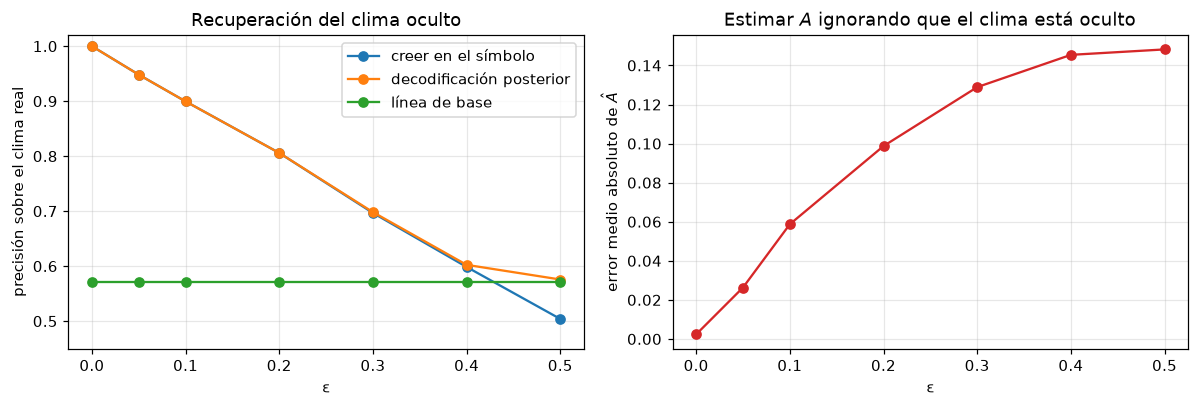

In [16]:
K_e, T_e = 100, 200
filas = []
for e in [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]:
    Be = np.array([[1 - e, e], [e, 1 - e]])
    q_, O_ = muestrear_hmm_lote(A, Be, pi, K_e, T_e, rng)
    gam_, _, _ = posteriores_lote(A, Be, pi, O_)
    Ah_obs, _, _ = estimar_cadena(O_, 2)
    filas.append({"ε": e, "creer en el símbolo": (O_ == q_).mean(), "decodificación posterior": (gam_.argmax(2) == q_).mean(),
                  "línea de base": pi_est.max(), "error de Â si se ignora lo oculto": np.abs(Ah_obs - A).mean()})
tab_e = pd.DataFrame(filas).set_index("ε"); display(tab_e.round(3))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
tab_e[["creer en el símbolo", "decodificación posterior", "línea de base"]].plot(ax=axs[0], marker="o")
axs[0].set(ylabel="precisión sobre el clima real", title="Recuperación del clima oculto", ylim=(0.45, 1.02))
tab_e["error de Â si se ignora lo oculto"].plot(ax=axs[1], marker="o", color="tab:red"); axs[1].set(ylabel="error medio absoluto de $\\hat{A}$", title="Estimar $A$ ignorando que el clima está oculto")
plt.tight_layout(); plt.show()

**Observaciones.**

- **Ocultamiento progresivo:** con $\varepsilon=0$ lo observado es el clima (la cadena observable del inciso 1); a medida que crece $\varepsilon$, los símbolos coinciden cada vez menos con el clima real (en el ejemplo, 3 de 60 días no coinciden con $\varepsilon=0.1$, 18 con $0.25$ y 33 con $0.5$, es decir, cerca de la mitad: el símbolo es independiente del clima). Las secuencias observadas pasan a tener "rachas" más cortas y más ruidosas que las del clima.
- **Recuperación del clima:** hasta $\varepsilon\approx0.3$ la decodificación posterior con el modelo completo apenas mejora la regla "creer en el símbolo" (por ejemplo $0.806$ vs. $0.806$ con $\varepsilon=0.2$; $0.698$ vs. $0.697$ con $0.3$). Es una propiedad de esta cadena: es poco persistente ($a_{11}=0.7$, $a_{22}=0.6$), así que los días vecinos aportan poca información sobre el día actual. Solo con ruido máximo ($\varepsilon=0.5$) el modelo ayuda: el símbolo da el 50 % (azar) y el modelo el 57.6 %, que coincide con la línea de base (siempre responder "lluvioso").
- **Si se ignora que el estado está oculto** y se estima $\mathbf{A}$ contando transiciones entre símbolos, el error crece de $0.002$ ($\varepsilon=0$) a $0.148$ ($\varepsilon=0.5$, donde las filas estimadas tienden a $(0.5,0.5)$). La secuencia observada **ya no es una cadena de Markov de matriz $\mathbf{A}$**: el ruido de observación borra la persistencia del clima. Por eso para un HMM se necesitan algoritmos específicos (Baum-Welch, Viterbi) que modelan la capa oculta.
- Con la $\mathbf{B}$ de la guía (3 símbolos) el ocultamiento es todavía mayor, porque ningún símbolo identifica al clima con certeza (ver sección siguiente).

---
## 6. Inciso 2a: decodificación del clima

Ahora se usa el HMM de la guía con 3 símbolos (Caminar, Comprar, Museo). Se genera una secuencia de **2000 días** de comportamientos y se calcula la **secuencia de climas más probable** con Viterbi. Como la simulación también guarda el clima verdadero, se puede medir cuánto difiere.

In [17]:
T_a = 2000
q_real, O_real = muestrear_hmm(A, B, pi, T_a, rng)
q_vit, lp_vit = viterbi(A, B, pi, O_real)
gam_a, _, ll_a = posteriores(A, B, pi, O_real)
q_post = gam_a.argmax(1)

lp_real = np.log(pi[q_real[0]] * B[q_real[0], O_real[0]]) + sum(np.log(A[q_real[t - 1], q_real[t]] * B[q_real[t], O_real[t]]) for t in range(1, T_a))
print(f"Primeros 60 días  — comportamiento: {''.join('CBM'[o] for o in O_real[:60])}   (C = caminar, B = comprar, M = museo)")
print(f"                  — clima real     : {''.join('LS'[i] for i in q_real[:60])}")
print(f"                  — clima Viterbi  : {''.join('LS'[i] for i in q_vit[:60])}\n")

print(f"Precisión de Viterbi (secuencia más probable)         : {(q_vit == q_real).mean():.3f}   ({int((q_vit != q_real).sum())} días distintos de {T_a})")
print(f"Precisión de la decodificación posterior (por día)     : {(q_post == q_real).mean():.3f}   ({int((q_post != q_real).sum())} días distintos)")
print(f"Precisión esperada según el modelo, mean(max γ_t)     : {gam_a.max(1).mean():.3f}")
print(f"Línea de base (siempre el estado más frecuente)        : {max((q_real == 0).mean(), (q_real == 1).mean()):.3f}")
print(f"\nlog P(O, q_Viterbi) = {lp_vit:.2f}   ≥   log P(O, q_real) = {lp_real:.2f}   →  Viterbi encuentra un camino al menos tan probable que el real: {lp_vit >= lp_real}")
print(f"Viterbi y posterior coinciden en {(q_vit == q_post).mean():.3%} de los días.")

conf = pd.crosstab(pd.Series([ESTADOS[i] for i in q_real], name="real"), pd.Series([ESTADOS[i] for i in q_vit], name="Viterbi"))
display(conf)
print("Proporción de errores por estado real:", {ESTADOS[i]: round(float((q_vit[q_real == i] != i).mean()), 3) for i in range(2)})

Primeros 60 días  — comportamiento: MCMCCBCBCBBCCBCMBBBBCBCBBBBBMCMCBCBMCBCCBMMBMMCCMBMMMBMMMBBB   (C = caminar, B = comprar, M = museo)
                  — clima real     : LLLSSSLLSLSSSLSLLLLLSSSSLLLLLSLSLSLLSLLSLLLSLSSSLSLLLSSLLLLL
                  — clima Viterbi  : LSLSSSSSSSSSSSSLLLLLSSSLLLLLLSLSSSLLSSSSLLLLLLSSLLLLLLLLLLLL

Precisión de Viterbi (secuencia más probable)         : 0.768   (464 días distintos de 2000)
Precisión de la decodificación posterior (por día)     : 0.770   (460 días distintos)
Precisión esperada según el modelo, mean(max γ_t)     : 0.775
Línea de base (siempre el estado más frecuente)        : 0.546

log P(O, q_Viterbi) = -2677.46   ≥   log P(O, q_real) = -3143.26   →  Viterbi encuentra un camino al menos tan probable que el real: True
Viterbi y posterior coinciden en 98.400% de los días.


Viterbi,Lluvioso,Soleado
real,,
Lluvioso,930,162
Soleado,302,606


Proporción de errores por estado real: {'Lluvioso': 0.148, 'Soleado': 0.333}


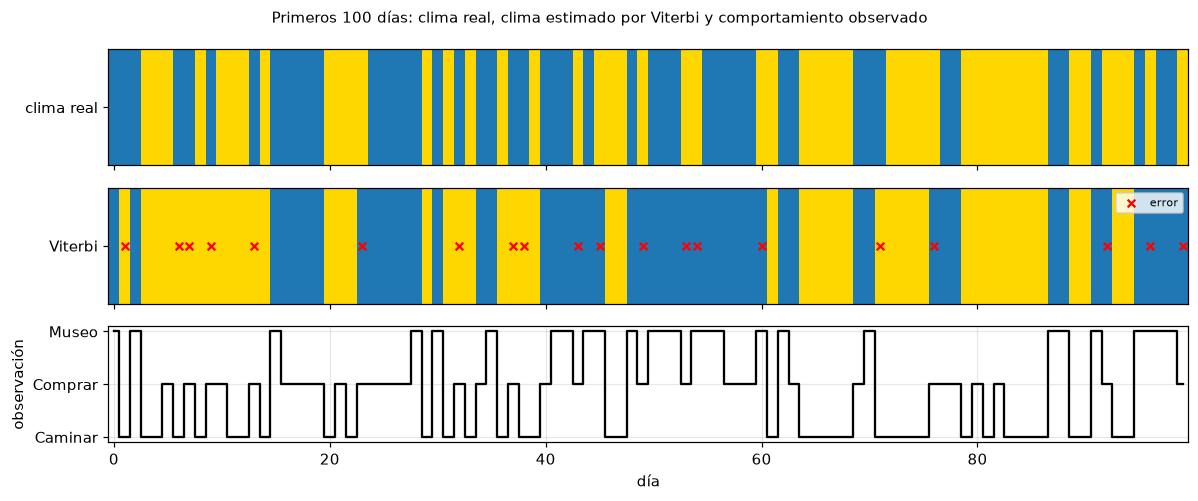

In [18]:
n_ver = 100
fig, axs = plt.subplots(3, 1, figsize=(11, 4.6), sharex=True)
axs[0].imshow(q_real[None, :n_ver], cmap=colores, aspect="auto", interpolation="nearest"); axs[0].set_yticks([0]); axs[0].set_yticklabels(["clima real"]); axs[0].grid(False)
axs[1].imshow(q_vit[None, :n_ver], cmap=colores, aspect="auto", interpolation="nearest"); axs[1].set_yticks([0]); axs[1].set_yticklabels(["Viterbi"]); axs[1].grid(False)
dif = (q_vit[:n_ver] != q_real[:n_ver])
axs[1].scatter(np.flatnonzero(dif), np.zeros(dif.sum()), marker="x", c="red", s=25, label="error"); axs[1].legend(loc="upper right", fontsize=7)
axs[2].step(range(n_ver), O_real[:n_ver], where="mid", color="k"); axs[2].set_yticks(range(3)); axs[2].set_yticklabels(SIMBOLOS); axs[2].set_xlabel("día")
axs[2].set_ylabel("observación"); plt.suptitle("Primeros 100 días: clima real, clima estimado por Viterbi y comportamiento observado", fontsize=10)
plt.tight_layout(); plt.show()

**Observaciones.**

- **Precisión:** Viterbi acierta el clima del **76.8 %** de los 2000 días (464 días distintos), y la decodificación posterior (por día) el **77.0 %**. Es mucho más que la línea de base (siempre "lluvioso": 54.6 % en esta secuencia). El valor esperado por el propio modelo, $\operatorname{mean}_t\max_i\gamma_t(i)=0.775$, coincide con la precisión medida: el modelo está **bien calibrado** respecto de su propia incertidumbre.
- **Viterbi y posterior** coinciden en el 98.4 % de los días; las pequeñas diferencias son esperables, porque Viterbi maximiza la secuencia completa y el posterior maximiza cada día por separado.
- **"Real" vs. "más probable":** la secuencia estimada por Viterbi tiene $\log P(O,\mathbf{q}^*)=-2677$, **mucho mayor** que la de la secuencia real ($-3143$). Es decir, Viterbi encuentra la secuencia más probable según el modelo, no la verdadera, y una realización real contiene sucesos poco probables (rachas muy cortas, por ejemplo) que Viterbi tiende a "alisar". La diferencia con el clima real no es un defecto del algoritmo sino un límite de la información: con emisiones que se superponen tanto, algunos días no se pueden distinguir.
- **Errores asimétricos:** se equivoca en el 14.8 % de los días lluviosos y en el **33 %** de los soleados. Un día soleado con "museo" o "comprar" (que ocurren con probabilidad 0.1 y 0.3 con sol, pero 0.5 y 0.4 con lluvia) se explica mejor como lluvioso, y además el estado lluvioso es más frecuente a priori.

---
## 7. Inciso 2b: entrenamiento

Se estiman los parámetros del HMM **a partir de las observaciones solamente** (sin ver el clima) con los dos métodos y se comparan con los valores reales. Se generan $K=30$ secuencias de $T=100$ días.

Como ambos métodos dependen de la inicialización, cada uno se ejecuta con **10 inicializaciones aleatorias** (matrices con filas muestreadas de una Dirichlet uniforme) y se conserva la mejor según el **criterio propio de cada método**: $\log P(O\mid\lambda)$ para Baum-Welch y $\log P(O,\mathbf{q}^*\mid\lambda)$ para el entrenamiento de Viterbi.

In [19]:
K_t, T_t = 30, 100
q_tr, O_tr = muestrear_hmm_lote(A, B, pi, K_t, T_t, rng)
ll_real = sum(log_verosimilitud(A, B, pi, O_tr[k]) for k in range(K_t))
print(f"log P(O) con los parámetros REALES = {ll_real:.2f}\n")

(mejor_bw, res_bw) = ajustar_con_reinicios(O_tr, 2, 3, baum_welch, 10, rng, n_iter=500, tol=1e-3)
(mejor_vt, res_vt) = ajustar_con_reinicios(O_tr, 2, 3, entrenar_viterbi, 10, rng)

ll_de = lambda r: sum(log_verosimilitud(r[0], r[1], r[2], O_tr[k]) for k in range(K_t))
tab_r = pd.DataFrame({
    "BW: log P(O)": [r[3][-1] for r in res_bw], "BW: iteraciones": [len(r[3]) for r in res_bw],
    "VT: log P(O,q*)": [r[3][-1] for r in res_vt], "VT: iteraciones": [len(r[3]) for r in res_vt],
    "VT: log P(O)": [ll_de(r) for r in res_vt]})
tab_r.index.name = "inicio"; display(tab_r.round(2))
print("¿La log-verosimilitud de Baum-Welch fue monótona no decreciente en todas las corridas?", all(np.all(np.diff(r[3]) > -1e-8) for r in res_bw))

log P(O) con los parámetros REALES = -3272.63



,BW: log P(O),BW: iteraciones,"VT: log P(O,q*)",VT: iteraciones,VT: log P(O)
inicio,,,,,
0,-3291.08,68,-3782.95,5,-3467.39
1,-3270.64,500,-3288.64,2,-3288.22
2,-3289.49,487,-3291.04,2,-3291.04
3,-3289.63,334,-3286.75,3,-3286.75
4,-3291.21,94,-3301.19,6,-3293.20
5,-3291.10,126,-3298.70,2,-3293.78
6,-3270.25,162,-3316.55,2,-3306.64
7,-3270.32,153,-3286.75,6,-3286.75
8,-3289.58,500,-3291.04,2,-3291.04


¿La log-verosimilitud de Baum-Welch fue monótona no decreciente en todas las corridas? True


VALORES REALES: A = [[0.7, 0.3], [0.4, 0.6]]   π = [0.6, 0.4]


,Caminar,Comprar,Museo
B real,,,
Lluvioso,0.1,0.4,0.5
Soleado,0.6,0.3,0.1


===== Baum-Welch (mejor de 10 inicios)  (estados reordenados con la permutación [1, 0]) =====


,Lluvioso,Soleado
Â,,
Lluvioso,0.838,0.162
Soleado,0.516,0.484


,Caminar,Comprar,Museo
B̂,,,
Lluvioso,0.159,0.418,0.423
Soleado,0.804,0.168,0.028


π̂ = [0.721 0.279] 

===== Entrenamiento de Viterbi (mejor de 10 inicios)  (estados reordenados con la permutación [1, 0]) =====


,Lluvioso,Soleado
Â,,
Lluvioso,0.365,0.635
Soleado,0.310,0.690


,Caminar,Comprar,Museo
B̂,,,
Lluvioso,0.000,0.000,1.0
Soleado,0.467,0.533,0.0


π̂ = [0.367 0.633] 



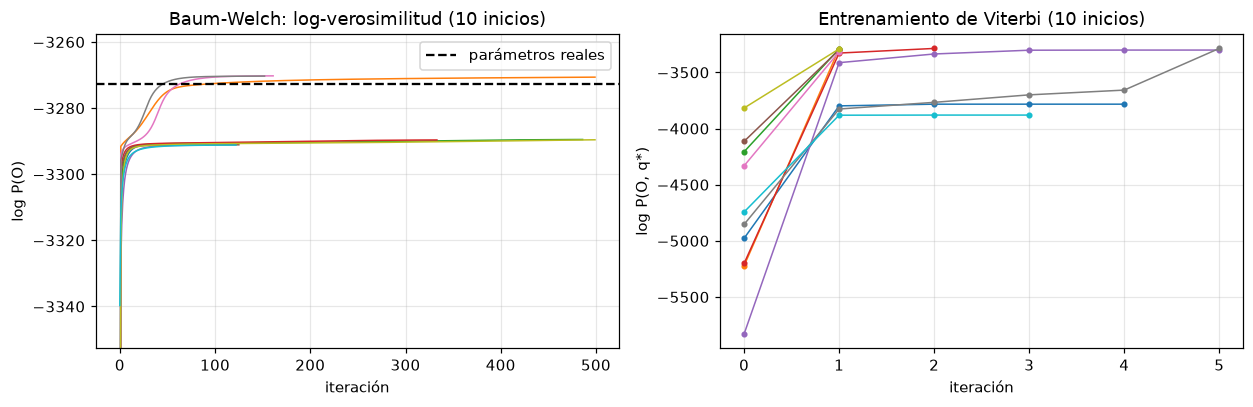

In [20]:
def mostrar(nombre, r):
    Ah, Bh, ph, perm = alinear_estados(r[0], r[1], r[2], A, B, pi)
    print(f"===== {nombre}  (estados reordenados con la permutación {perm}) =====")
    display(pd.DataFrame(Ah, index=ESTADOS, columns=ESTADOS).round(3).rename_axis("Â"))
    display(pd.DataFrame(Bh, index=ESTADOS, columns=SIMBOLOS).round(3).rename_axis("B̂"))
    print("π̂ =", ph.round(3), "\n")
    return Ah, Bh, ph


print("VALORES REALES: A =", A.tolist(), "  π =", pi.tolist()); display(pd.DataFrame(B, index=ESTADOS, columns=SIMBOLOS).rename_axis("B real"))
est_bw = mostrar("Baum-Welch (mejor de 10 inicios)", mejor_bw)
est_vt = mostrar("Entrenamiento de Viterbi (mejor de 10 inicios)", mejor_vt)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8))
for r in res_bw: axs[0].plot(r[3], lw=1)
axs[0].axhline(ll_real, color="k", ls="--", label="parámetros reales"); axs[0].set(xlabel="iteración", ylabel="log P(O)", title="Baum-Welch: log-verosimilitud (10 inicios)", ylim=(ll_real - 80, ll_real + 15)); axs[0].legend()
for r in res_vt: axs[1].plot(r[3], "o-", ms=3, lw=1)
axs[1].set(xlabel="iteración", ylabel="log P(O, q*)", title="Entrenamiento de Viterbi (10 inicios)"); 
plt.tight_layout(); plt.show()

In [21]:
# Verificación: ¿lo que devuelve Baum-Welch es el estimador de máxima verosimilitud, o falló la optimización?
# Se reinicia desde los parámetros REALES y se corre hasta una convergencia más fina; si llega al mismo punto que el mejor inicio aleatorio,
# el error respecto de los parámetros reales es propio del estimador (varianza del dato) y no del algoritmo.
r_v = baum_welch(O_tr, A, B, pi, n_iter=5000, tol=1e-7)
Ah_v, Bh_v, ph_v, _ = alinear_estados(r_v[0], r_v[1], r_v[2], A, B, pi)
Ah_b, Bh_b, ph_b, _ = alinear_estados(mejor_bw[0], mejor_bw[1], mejor_bw[2], A, B, pi)
print(f"log P(O):  desde parámetros reales = {r_v[3][-1]:.2f} ({len(r_v[3])} iter.)   |   mejor inicio aleatorio = {mejor_bw[3][-1]:.2f}   |   parámetros reales sin entrenar = {ll_real:.2f}")
print(f"Error medio |Â-A|: desde reales = {np.abs(Ah_v - A).mean():.3f}   mejor aleatorio = {np.abs(Ah_b - A).mean():.3f}")
print(f"Error medio |B̂-B|: desde reales = {np.abs(Bh_v - B).mean():.3f}   mejor aleatorio = {np.abs(Bh_b - B).mean():.3f}")
print("Diferencia máxima entre ambas soluciones (A, B, π):", np.abs(Ah_v - Ah_b).max().round(3), np.abs(Bh_v - Bh_b).max().round(3), np.abs(ph_v - ph_b).max().round(3))

log P(O):  desde parámetros reales = -3270.15 (2752 iter.)   |   mejor inicio aleatorio = -3270.25   |   parámetros reales sin entrenar = -3272.63
Error medio |Â-A|: desde reales = 0.144   mejor aleatorio = 0.127
Error medio |B̂-B|: desde reales = 0.107   mejor aleatorio = 0.094
Diferencia máxima entre ambas soluciones (A, B, π): 0.021 0.037 0.03


**Observaciones.**

- **Baum-Welch:** la log-verosimilitud no decreció en ninguna iteración de ninguna corrida (propiedad teórica del EM, verificada). Pero de los 10 inicios, **solo 3 llegan al mejor máximo** ($\log P(O)\approx-3270.3$, incluso algo mayor que la de los parámetros reales, $-3272.6$, porque el estimador se ajusta a la muestra finita); los otros 7 quedan en un máximo local o meseta peor ($\approx-3290$). Hace falta **probar varios inicios** y quedarse con el de mayor verosimilitud.
- **Calidad de la estimación (Baum-Welch):** $\hat{\mathbf{A}}=\begin{pmatrix}0.84&0.16\\0.52&0.48\end{pmatrix}$ (real $\begin{pmatrix}0.7&0.3\\0.4&0.6\end{pmatrix}$), $\hat{\mathbf{B}}$ razonablemente cercana (por ejemplo, Soleado: Caminar $0.80$ vs. $0.6$; Museo $0.03$ vs. $0.1$) y $\hat{\boldsymbol\pi}=(0.72,0.28)$ (real $(0.6,0.4)$). La verificación de la celda anterior muestra que **no es un fallo de la optimización**: si se parte de los parámetros reales, Baum-Welch converge casi al mismo punto ($\log P(O)=-3270.15$, con diferencias de a lo sumo $0.04$ en los parámetros). El error es entonces el del **estimador de máxima verosimilitud** con 3000 observaciones: con dos estados y emisiones que se superponen tanto, los parámetros (sobre todo $\mathbf{A}$) están poco determinados por los datos.
- **Entrenamiento de Viterbi:** converge en muy pocas iteraciones (2 a 6), pero a **soluciones malas**: con el mejor inicio según su propio criterio, $\hat{\mathbf{B}}$ es degenerada (Lluvioso emite solo "Museo" con probabilidad 1; Soleado solo "Caminar" o "Comprar"), $\hat{\mathbf{A}}=\begin{pmatrix}0.37&0.63\\0.31&0.69\end{pmatrix}$ es muy distinta de la real y su $\log P(O)=-3286.8$ es **16 nats peor** que la de Baum-Welch ($-3270.2$). Algunos inicios terminan aún peor ($\log P(O)\approx-3470$).
- **Por qué:** el entrenamiento de Viterbi maximiza $P(O,\mathbf{q}\mid\lambda)$ conjuntamente en los parámetros y en los caminos (asignaciones "duras"), y eso favorece modelos con emisiones **deterministas** (cada símbolo asociado a un único estado), que hacen más probable el camino conjunto aunque expliquen peor los datos ($P(O)$ menor). Con emisiones que se superponen tanto, el sesgo es grande. Baum-Welch, en cambio, maximiza $P(O\mid\lambda)$ con asignaciones blandas.

### Efecto de la cantidad de datos

Se repite el entrenamiento con distinta cantidad de secuencias $K\in\{5,20,80\}$ (de $T=100$ días), 8 repeticiones de cada una, con 5 inicios por ajuste. Se mide el error medio absoluto (luego de alinear los estados) de $\hat{\mathbf{A}}$, $\hat{\mathbf{B}}$ y $\hat{\boldsymbol\pi}$.

A             B             π       
                mean    std   mean    std   mean    std
método     K                                           
Baum-Welch 5   0.120  0.067  0.086  0.055  0.330  0.209
           20  0.076  0.040  0.048  0.017  0.190  0.139
           80  0.080  0.059  0.048  0.027  0.162  0.071
Viterbi    5   0.369  0.178  0.203  0.067  0.325  0.237
           20  0.292  0.164  0.214  0.073  0.350  0.185
           80  0.338  0.207  0.192  0.042  0.280  0.113

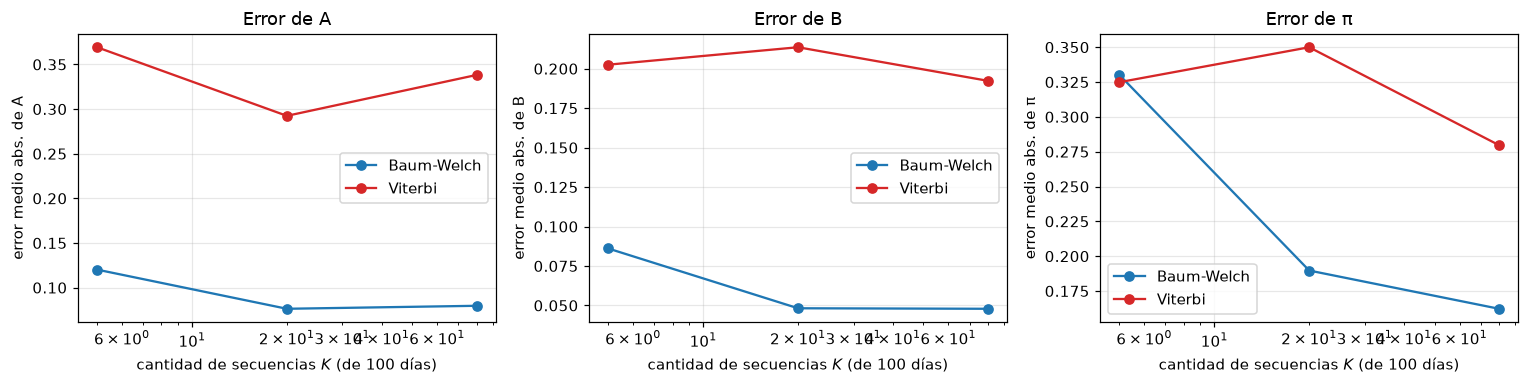

In [22]:
Kd = [5, 20, 80]; Rep = 8; filas = []
for K_ in Kd:
    for rep in range(Rep):
        _, O_ = muestrear_hmm_lote(A, B, pi, K_, 100, rng)
        for nombre, fn, kw in [("Baum-Welch", baum_welch, dict(n_iter=500, tol=1e-3)), ("Viterbi", entrenar_viterbi, {})]:
            m, _ = ajustar_con_reinicios(O_, 2, 3, fn, 5, rng, **kw)
            Ah, Bh, ph, _ = alinear_estados(m[0], m[1], m[2], A, B, pi)
            filas.append({"K": K_, "método": nombre, "A": np.abs(Ah - A).mean(), "B": np.abs(Bh - B).mean(), "π": np.abs(ph - pi).mean()})
res_d = pd.DataFrame(filas).groupby(["método", "K"]).agg(["mean", "std"]).round(3)
display(res_d)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
g = pd.DataFrame(filas).groupby(["método", "K"]).mean().reset_index()
for ax, par in zip(axs, ["A", "B", "π"]):
    for nombre, c in [("Baum-Welch", "tab:blue"), ("Viterbi", "tab:red")]:
        s = g[g["método"] == nombre]; ax.plot(s["K"], s[par], "o-", color=c, label=nombre)
    ax.set(xscale="log", xlabel="cantidad de secuencias $K$ (de 100 días)", ylabel=f"error medio abs. de {par}", title=f"Error de {par}"); ax.legend()
plt.tight_layout(); plt.show()

**Observaciones.**

- **Baum-Welch:** el error de $\hat{\mathbf{A}}$ baja de $0.12$ ($K=5$) a $0.076$ ($K=20$), el de $\hat{\mathbf{B}}$ de $0.086$ a $0.048$ y el de $\hat{\boldsymbol\pi}$ de $0.33$ a $0.19$. De $K=20$ a $K=80$ no se ve una mejora clara en $\hat{\mathbf{A}}$ y $\hat{\mathbf{B}}$ (con 8 repeticiones y desvíos de 0.02 a 0.07 entre repeticiones, las diferencias no son significativas); $\hat{\boldsymbol\pi}$ sigue bajando ($0.16$). Es consistente con lo visto antes: en este modelo **la estimación de $\mathbf{A}$ converge lentamente** y los errores de 0.05 a 0.1 con miles de observaciones no son raros.
- **Viterbi:** los errores son de 2 a 5 veces mayores ($\hat{\mathbf{A}}$: $0.29$ a $0.37$; $\hat{\mathbf{B}}$: $\approx0.2$) y **no mejoran al agregar datos**: es un estimador **sesgado** (no converge a los parámetros reales aunque haya más datos), por la razón explicada arriba.
- **Resumen de la comparación:** Baum-Welch (EM) es claramente superior en este problema. El entrenamiento de Viterbi es mucho más barato (pocas iteraciones, sin cálculos de posteriores) y puede ser razonable cuando los estados están bien separados por las emisiones, pero con estados poco distinguibles produce modelos degenerados.

---
## 8. Inciso 2c: clasificación de turistas

**Planteo.** Se tienen varios modelos $\lambda_1,\dots,\lambda_K$, uno por **tipo de turista**. Un turista recién llegado produce durante su primera semana una secuencia de actividades $O_1,\dots,O_7$. Se lo clasifica en el tipo cuyo modelo da **mayor verosimilitud** $P(O\mid\lambda_k)$ (calculada con el algoritmo forward); si se conocen las proporciones de cada tipo, se suma $\log P(k)$ (regla de Bayes). Los modelos se **entrenan** de antemano con Baum-Welch, usando secuencias de turistas de tipo conocido.

**Modelos usados en el ejemplo (inventados, solo ilustrativos).** El clima es el mismo para todos ($\mathbf{A}$, $\boldsymbol\pi$), y cambia el comportamiento ante cada clima ($\mathbf{B}$):

| Tipo | Lluvioso: Caminar / Comprar / Museo | Soleado: Caminar / Comprar / Museo |
|:--|:-:|:-:|
| **Estándar** (el de la guía) | 0.10 / 0.40 / 0.50 | 0.60 / 0.30 / 0.10 |
| **Caminante** | 0.50 / 0.15 / 0.35 | 0.85 / 0.10 / 0.05 |
| **Comprador** | 0.05 / 0.60 / 0.35 | 0.25 / 0.65 / 0.10 |

In [23]:
TIPOS = {"Estándar": B,
         "Caminante": np.array([[0.50, 0.15, 0.35], [0.85, 0.10, 0.05]]),
         "Comprador": np.array([[0.05, 0.60, 0.35], [0.25, 0.65, 0.10]])}
nombres_t = list(TIPOS)


def clasificar(O, modelos, log_prior=None):
    '''O: secuencia de símbolos. modelos: dict nombre -> (A, B, pi). Devuelve (índice ganador, log-verosimilitudes).'''
    ll = np.array([log_verosimilitud(*modelos[n], O) for n in modelos])
    if log_prior is not None: ll = ll + log_prior
    return int(np.argmax(ll)), ll


modelos_reales = {n: (A, Bk, pi) for n, Bk in TIPOS.items()}

# --- Un ejemplo ---
q_, O_ej = muestrear_hmm(A, TIPOS["Caminante"], pi, 7, rng)
k_, ll_ = clasificar(O_ej, modelos_reales)
post = np.exp(ll_ - ll_.max()); post /= post.sum()
print("Primera semana de un turista (verdadero tipo: Caminante):", [SIMBOLOS[o] for o in O_ej])
display(pd.DataFrame({"log P(O|λ)": ll_, "posterior (a priori uniforme)": post}, index=nombres_t).round(3))
print("→ clasificado como:", nombres_t[k_])

Primera semana de un turista (verdadero tipo: Caminante): ['Caminar', 'Caminar', 'Caminar', 'Caminar', 'Caminar', 'Caminar', 'Caminar']


,log P(O|λ),posterior (a priori uniforme)
Estándar,-7.002,0.016
Caminante,-2.871,0.984
Comprador,-13.009,0.000


→ clasificado como: Caminante


### Desempeño con los modelos verdaderos y efecto del largo de la ventana

Como referencia se miden la **matriz de confusión** a los 7 días y la **exactitud en función de la cantidad de días observados** (1 a 30), con modelos exactos (es el mejor desempeño posible para este esquema). Se usan 500 turistas por tipo y por largo.

In [24]:
def exactitud_vs_dias(modelos, largos, n=500, rng=rng):
    acc = []; conf7 = None
    for T_ in largos:
        conf = np.zeros((3, 3))
        for k, nom in enumerate(nombres_t):
            _, Ol = muestrear_hmm_lote(A, TIPOS[nom], pi, n, T_, rng)
            for O in Ol: conf[k, clasificar(O, modelos)[0]] += 1
        conf /= n; acc.append(np.diag(conf).mean())
        if T_ == 7: conf7 = conf
    return np.array(acc), conf7


largos = [1, 2, 3, 5, 7, 10, 14, 21, 30]
acc_real, conf7_real = exactitud_vs_dias(modelos_reales, largos)
print("Matriz de confusión a los 7 días (modelos verdaderos; filas = tipo real, columnas = tipo asignado):")
display(pd.DataFrame(conf7_real, index=nombres_t, columns=nombres_t).round(2))
print("Exactitud a los 7 días:", round(float(np.diag(conf7_real).mean()), 3))

Matriz de confusión a los 7 días (modelos verdaderos; filas = tipo real, columnas = tipo asignado):


,Estándar,Caminante,Comprador
Estándar,0.60,0.19,0.21
Caminante,0.15,0.85,0.00
Comprador,0.24,0.01,0.76


Exactitud a los 7 días: 0.737


### Modelos aprendidos de los datos

En la práctica los modelos no se conocen. Se entrena un HMM por tipo con Baum-Welch (30 turistas de 30 días por tipo, 5 inicios aleatorios por modelo, la mejor log-verosimilitud) y se clasifica con ellos.

Estándar  : error medio |B̂ - B| = 0.063   error medio |Â - A| = 0.052


Caminante : error medio |B̂ - B| = 0.297   error medio |Â - A| = 0.159


Comprador : error medio |B̂ - B| = 0.088   error medio |Â - A| = 0.648



Matriz de confusión a los 7 días con los modelos APRENDIDOS:


,Estándar,Caminante,Comprador
Estándar,0.55,0.21,0.24
Caminante,0.17,0.82,0.00
Comprador,0.25,0.01,0.74


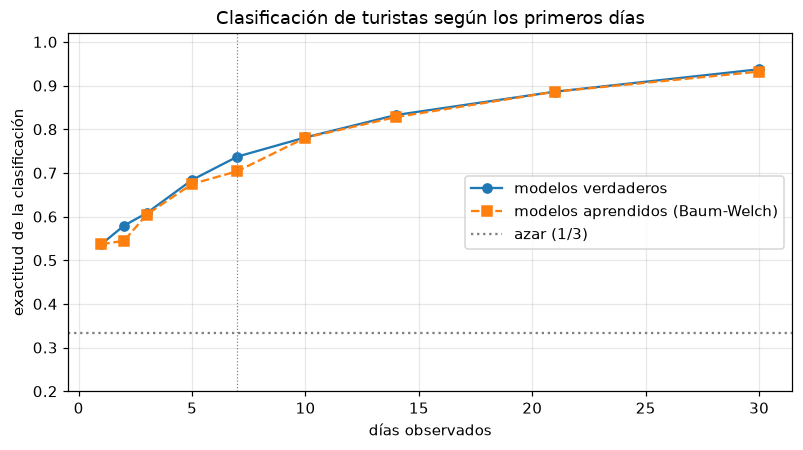

días,1,2,3,5,7,10,14,21,30
modelos verdaderos,0.537,0.579,0.608,0.684,0.737,0.781,0.833,0.886,0.937
modelos aprendidos,0.537,0.545,0.605,0.675,0.704,0.781,0.828,0.886,0.932


In [25]:
modelos_apr = {}
for nom in nombres_t:
    _, Otr = muestrear_hmm_lote(A, TIPOS[nom], pi, 30, 30, rng)
    m, _ = ajustar_con_reinicios(Otr, 2, 3, baum_welch, 5, rng, n_iter=500, tol=1e-3)
    modelos_apr[nom] = (m[0], m[1], m[2])
    Ah, Bh, ph, perm = alinear_estados(m[0], m[1], m[2], A, TIPOS[nom], pi)
    print(f"{nom:10s}: error medio |B̂ - B| = {np.abs(Bh - TIPOS[nom]).mean():.3f}   error medio |Â - A| = {np.abs(Ah - A).mean():.3f}")

acc_apr, conf7_apr = exactitud_vs_dias(modelos_apr, largos)
print("\nMatriz de confusión a los 7 días con los modelos APRENDIDOS:")
display(pd.DataFrame(conf7_apr, index=nombres_t, columns=nombres_t).round(2))

fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.plot(largos, acc_real, "o-", label="modelos verdaderos"); ax.plot(largos, acc_apr, "s--", label="modelos aprendidos (Baum-Welch)")
ax.axhline(1 / 3, color="gray", ls=":", label="azar (1/3)"); ax.axvline(7, color="gray", ls=":", lw=0.8)
ax.set(xlabel="días observados", ylabel="exactitud de la clasificación", title="Clasificación de turistas según los primeros días", ylim=(0.2, 1.02)); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({"modelos verdaderos": acc_real, "modelos aprendidos": acc_apr}, index=pd.Index(largos, name="días")).round(3).T)

**Observaciones.**

- **Un caso concreto:** una semana en que el turista solo camina da $\log P(O\mid\lambda)=-2.9$ para "Caminante", $-7.0$ para "Estándar" y $-13.0$ para "Comprador"; con a priori uniforme, la probabilidad posterior de "Caminante" es $0.98$.
- **Desempeño con los modelos verdaderos:** a los 7 días la exactitud es **73.7 %** (frente a 33 % del azar). El tipo más fácil es el *Caminante* (85 %) y el más difícil el *Estándar* (60 %), cuyo comportamiento queda "en el medio" de los otros dos y se confunde con ambos (19 % y 21 %).
- **Efecto de la ventana:** la exactitud crece con los días observados: $53.7\,\%$ con 1 día, $60.8\,\%$ con 3, $73.7\,\%$ con 7, $83.3\,\%$ con 14 y $93.7\,\%$ con 30. Una semana da información útil pero **no concluyente**; la diferencia entre las log-verosimilitudes de los modelos crece con cada día observado.
- **Modelos aprendidos:** con un HMM por tipo entrenado con Baum-Welch (30 turistas de 30 días), la exactitud a los 7 días es $70.4\,\%$ (3 puntos menos que con los modelos verdaderos, una diferencia apenas mayor que el error de simulación de $\approx\pm1.2$ puntos), y con 10 días o más es prácticamente igual ($78.1\,\%$, $82.8\,\%$, $88.6\,\%$ y $93.2\,\%$ con 10, 14, 21 y 30 días). Esto ocurre aunque los **parámetros aprendidos pueden estar lejos de los reales** (por ejemplo, el error medio de $\hat{\mathbf{B}}$ es $0.30$ para el tipo Caminante y el de $\hat{\mathbf{A}}$ es $0.65$ para el Comprador): la clasificación solo depende de $P(O\mid\lambda)$, que es lo que Baum-Welch maximiza, y no de que cada parámetro coincida con el verdadero.
- **Extensiones:** si se conocen las proporciones de cada tipo, se suma $\log P(k)$ (regla de Bayes); y para detectar turistas que no encajan en ningún tipo conviene rechazar la clasificación cuando la mayor verosimilitud por día sea baja.

---
## 9. Conclusiones

1. **Cadena de Markov observable (1a, 1b).** El modelo generativo (sortear $q_1\sim\boldsymbol\pi$ y luego $q_{t+1}\sim\mathbf{A}_{q_t,\cdot}$) reproduce la distribución estacionaria $\boldsymbol\pi^*=(4/7,3/7)$, la matriz de transición y las rachas geométricas (medias $1/(1-a_{ii})$).
2. **Estimación en la cadena (1c).** $\hat{\mathbf{A}}$ mejora con el número **total** de transiciones $K\cdot T$ (error $\propto1/\sqrt{KT}$), mientras que $\hat{\boldsymbol\pi}$ mejora solo con el número de **secuencias** $K$ (cada secuencia aporta un único dato). El modelo con una matriz constante **no es válido para todas las estaciones**: el clima cambia a lo largo del año y la matriz única es un promedio que ajusta mal cada estación.
3. **Modelo oculto (1d).** Se obtiene agregando una matriz de emisión $\mathbf{B}$; con $\mathbf{B}=\mathbf{I}$ se recupera la cadena observable. A medida que el estado se oculta, el clima se recupera peor (con la cadena de este ejercicio, el modelo mejora poco la regla "creer en el símbolo" mientras $\varepsilon\le0.3$) y estimar $\mathbf{A}$ como si el estado fuera observable da resultados sesgados.
4. **Decodificación (2a).** Viterbi acierta el 77 % del clima real con el HMM de la guía (frente al 55 % a 57 % de la línea de base), prácticamente igual que la decodificación posterior (coinciden en el 98 % de los días). La secuencia de Viterbi es **más probable que la real**: la diferencia con el clima real se debe a la información limitada de las observaciones, no a un error del algoritmo.
5. **Entrenamiento (2b).** Baum-Welch logra estimaciones razonables, con log-verosimilitud monótona, pero necesita varios inicios (solo 3 de 10 llegaron al mejor máximo) y los parámetros, sobre todo $\mathbf{A}$, tienen un error de 0.05 a 0.15 incluso con miles de observaciones. El entrenamiento de Viterbi es más rápido pero **sesgado**: produce emisiones degeneradas y errores 2 a 5 veces mayores, que no mejoran con más datos.
6. **Clasificación (2c).** Se clasifica con el modelo de mayor $P(O\mid\lambda)$ calculado con forward. Con los tres tipos de ejemplo, una semana da 74 % de aciertos (70 % con modelos aprendidos con Baum-Welch) y la exactitud crece con los días observados (94 % con 30 días). Los modelos pueden entrenarse con datos etiquetados, y el esquema se extiende con probabilidades a priori y con rechazo de casos dudosos.